In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [ ]:
file_path = "/content/drive/MyDrive/Loan/Loan_Data_Preprocessed.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (529, 22)


In [ ]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,...,Log_ApplicantIncome,Log_CoapplicantIncome,Log_LoanAmount,Log_TotalIncome,EMI,LoanToIncome,BalanceIncome,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,0,0.966197,-0.931152,0.041113,0.264335,1.0,...,1.064349,-1.136980,0.210422,0.413662,-0.121280,-0.344145,0.276025,0,0,1
1,1,1,1,0,0,0.275041,0.156993,0.041113,0.264335,1.0,...,0.489606,0.793137,0.210422,0.524036,-0.121280,-0.452958,0.400510,1,0,0
2,1,1,0,0,1,-0.589178,-0.931152,-1.351903,0.264335,1.0,...,-0.508781,-1.136980,-1.414162,-1.403885,-0.486227,-0.330083,-1.100909,0,0,1
3,1,1,0,1,0,-0.816834,0.770337,-0.138631,0.264335,1.0,...,-0.861370,0.910959,0.051659,-0.045619,-0.168370,-0.043525,-0.179619,0,0,1
4,1,0,0,0,0,1.048634,-0.931152,0.333197,0.264335,1.0,...,1.124410,-1.136980,0.448522,0.483055,-0.044759,-0.141872,0.335124,0,0,1


In [ ]:
print("Dataset Information")
print("-" * 50)

df.info()

Dataset Information
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 529 entries, 0 to 528
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   529 non-null    int64  
 1   Married                  529 non-null    int64  
 2   Dependents               529 non-null    int64  
 3   Education                529 non-null    int64  
 4   Self_Employed            529 non-null    int64  
 5   ApplicantIncome          529 non-null    float64
 6   CoapplicantIncome        529 non-null    float64
 7   LoanAmount               529 non-null    float64
 8   Loan_Amount_Term         529 non-null    float64
 9   Credit_History           529 non-null    float64
 10  Loan_Status              529 non-null    int64  
 11  TotalIncome              529 non-null    float64
 12  Log_ApplicantIncome      529 non-null    float64
 13  Log_Coapp

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Gender                     0
Married                    0
Dependents                 0
Education                  0
Self_Employed              0
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                 0
Loan_Amount_Term           0
Credit_History             0
Loan_Status                0
TotalIncome                0
Log_ApplicantIncome        0
Log_CoapplicantIncome      0
Log_LoanAmount             0
Log_TotalIncome            0
EMI                        0
LoanToIncome               0
BalanceIncome              0
Property_Area_Rural        0
Property_Area_Semiurban    0
Property_Area_Urban        0
dtype: int64


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Gender,529.0,8.147448e-01,0.388872,0.000000,1.000000,1.000000,1.000000,1.000000
Married,529.0,6.502836e-01,0.477332,0.000000,0.000000,1.000000,1.000000,1.000000
Dependents,529.0,7.183365e-01,0.995284,0.000000,0.000000,0.000000,1.000000,3.000000
Education,529.0,2.457467e-01,0.430937,0.000000,0.000000,0.000000,0.000000,1.000000
Self_Employed,529.0,1.134216e-01,0.317408,0.000000,0.000000,0.000000,0.000000,1.000000
ApplicantIncome,529.0,1.242442e-16,1.000947,-1.681052,-0.715835,-0.261069,0.445373,3.308268
CoapplicantIncome,529.0,2.350567e-17,1.000947,-0.931152,-0.931152,-0.029176,0.632515,3.127744
LoanAmount,529.0,-4.701133e-17,1.000947,-2.632579,-0.587991,-0.048759,0.557878,3.006890
Loan_Amount_Term,529.0,3.525850e-16,1.000947,-5.178831,0.264335,0.264335,0.264335,2.141288
Credit_History,529.0,8.525520e-01,0.354888,0.000000,1.000000,1.000000,1.000000,1.000000


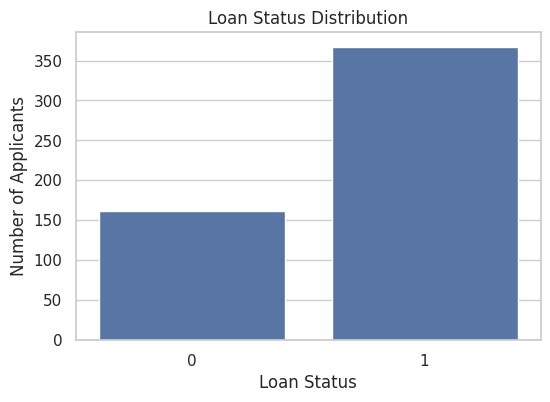

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Loan_Status"
)

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.show()

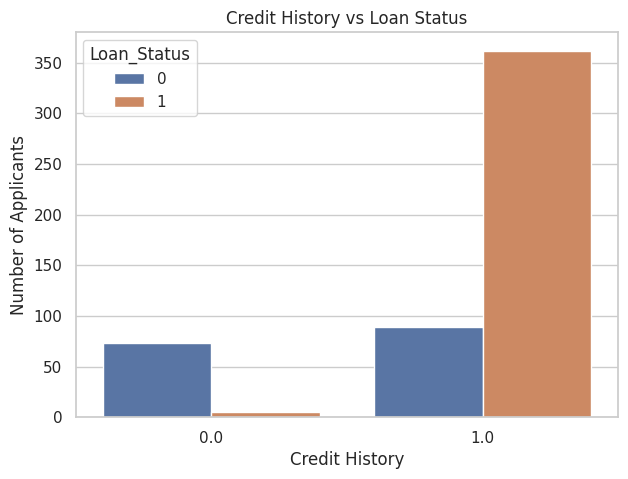

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Credit_History",
    hue="Loan_Status"
)

plt.title("Credit History vs Loan Status")
plt.xlabel("Credit History")
plt.ylabel("Number of Applicants")

plt.show()

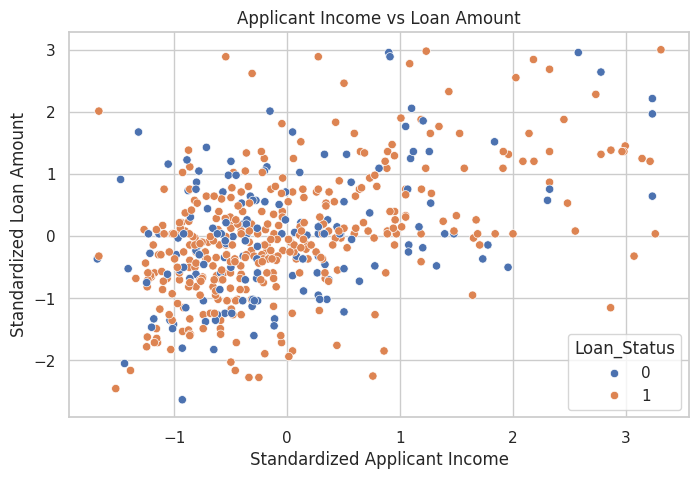

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="ApplicantIncome",
    y="LoanAmount",
    hue="Loan_Status"
)

plt.title("Applicant Income vs Loan Amount")
plt.xlabel("Standardized Applicant Income")
plt.ylabel("Standardized Loan Amount")

plt.show()

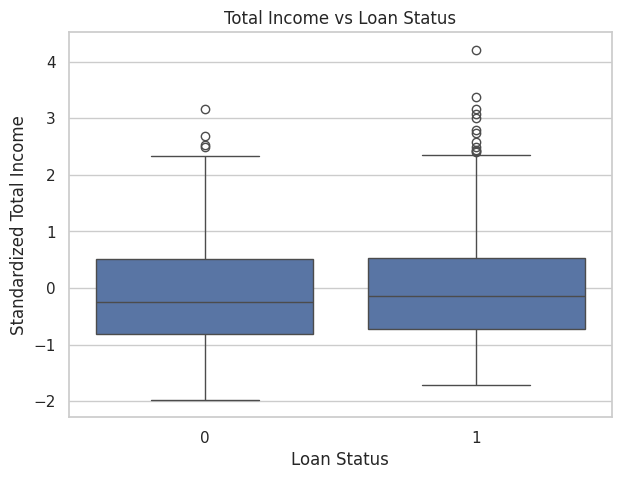

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Loan_Status",
    y="TotalIncome"
)

plt.title("Total Income vs Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Standardized Total Income")

plt.show()

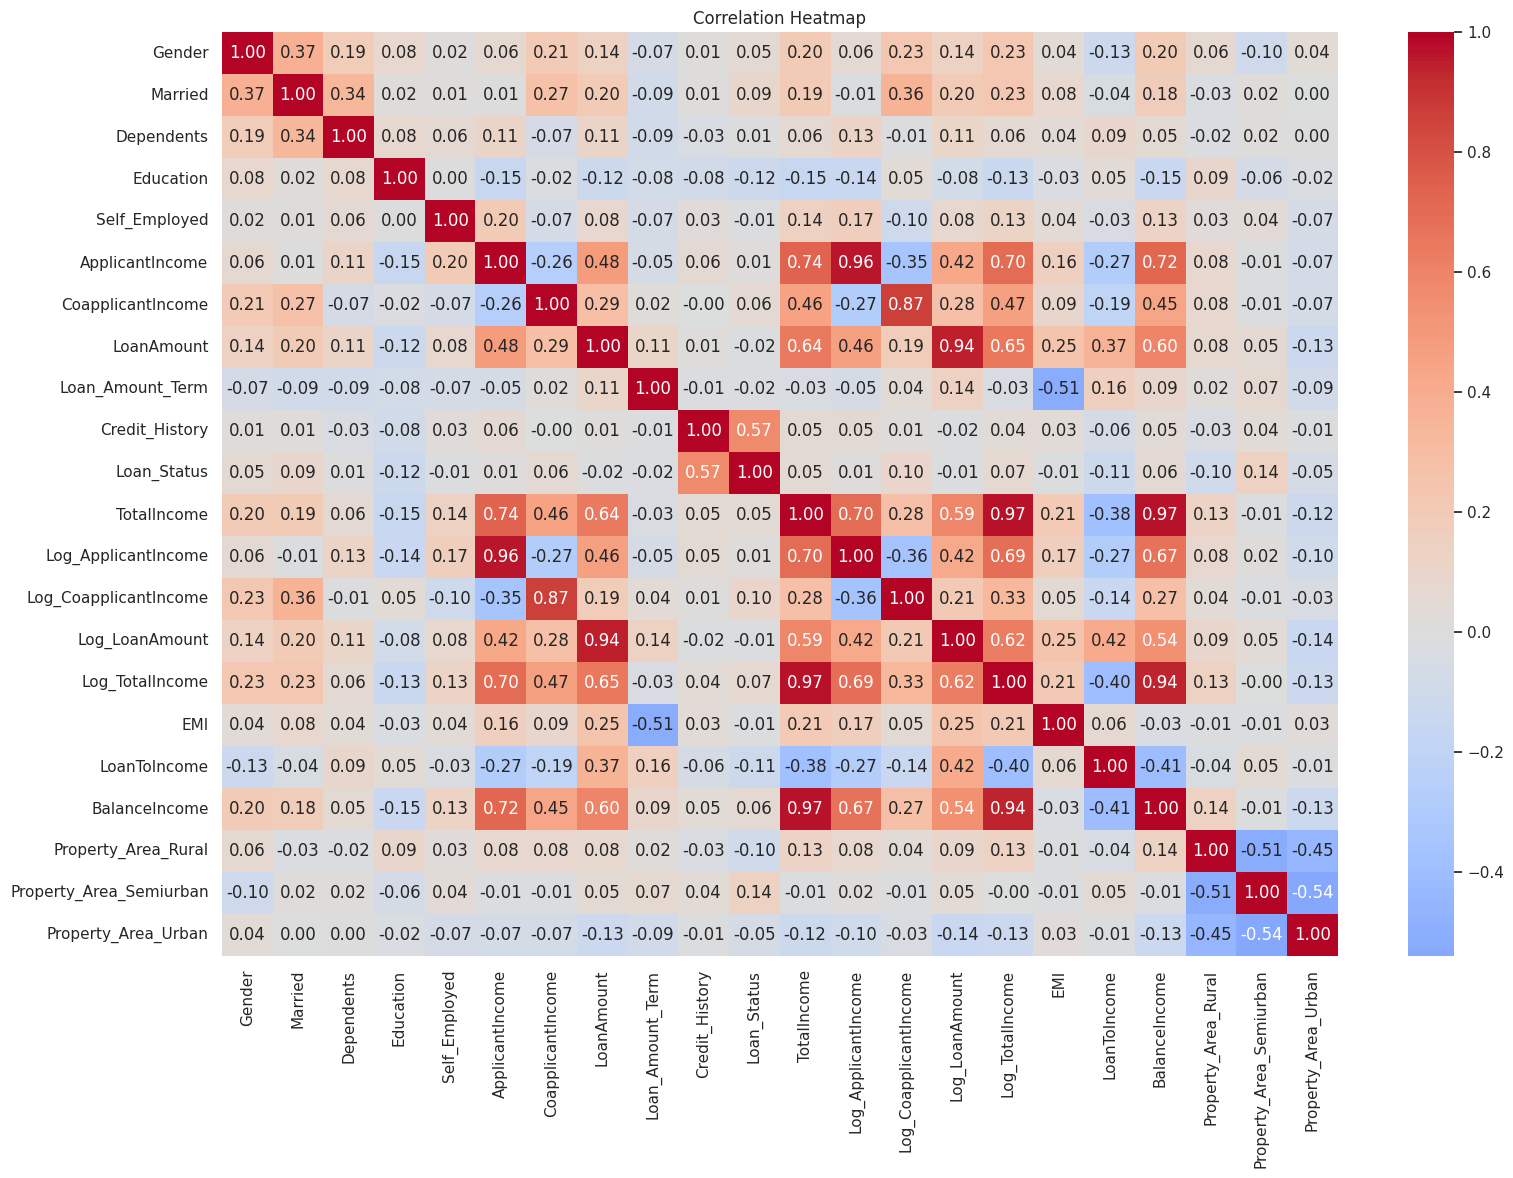

In [ ]:
plt.figure(figsize=(18, 12))

corr = df.corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

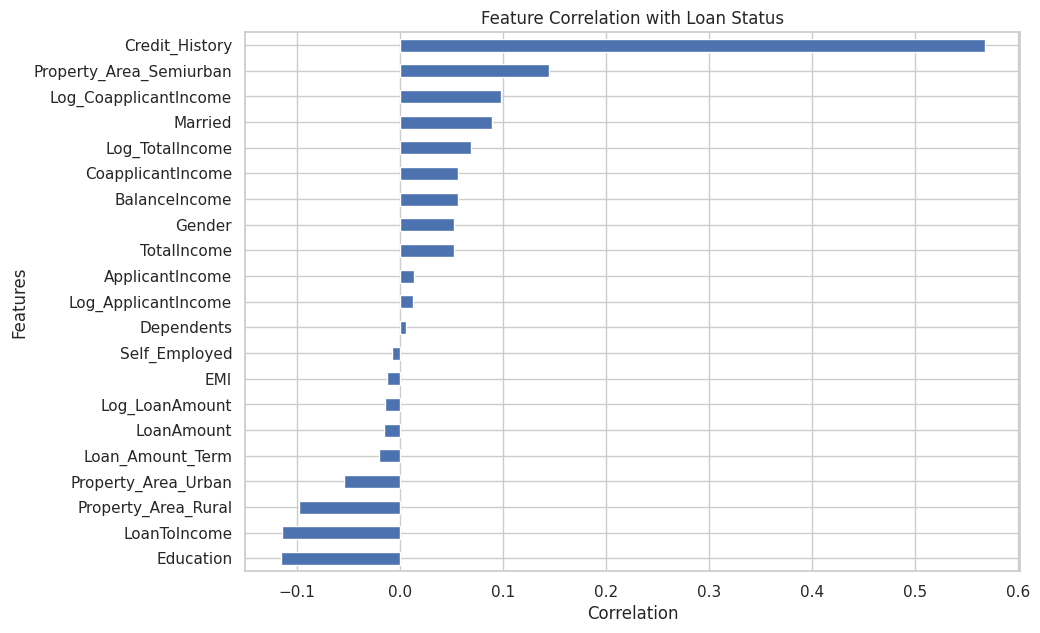

In [ ]:
target_corr = (
    df.corr()["Loan_Status"]
    .drop("Loan_Status")
    .sort_values()
)

plt.figure(figsize=(10, 7))

target_corr.plot(kind="barh")

plt.title("Feature Correlation with Loan Status")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.show()

In [ ]:
X = df.drop("Loan_Status", axis=1)

y = df["Loan_Status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (529, 21)
y shape: (529,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting Data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training Data:
X_train: (423, 21)
y_train: (423,)

Testing Data:
X_test: (106, 21)
y_test: (106,)


In [ ]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
Loan_Status
1    293
0    130
Name: count, dtype: int64

Testing target distribution:
Loan_Status
1    74
0    32
Name: count, dtype: int64


In [ ]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 0
 0 0 0 0 1 0 1 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1 1 1 1 1 0 1 1 1 0 0]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.8584905660377359
Accuracy Percentage: 85.85 %


In [ ]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Rejected", "Approved"]
    )
)

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.87      0.62      0.73        32
    Approved       0.86      0.96      0.90        74

    accuracy                           0.86       106
   macro avg       0.86      0.79      0.82       106
weighted avg       0.86      0.86      0.85       106



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[20 12]
 [ 3 71]]


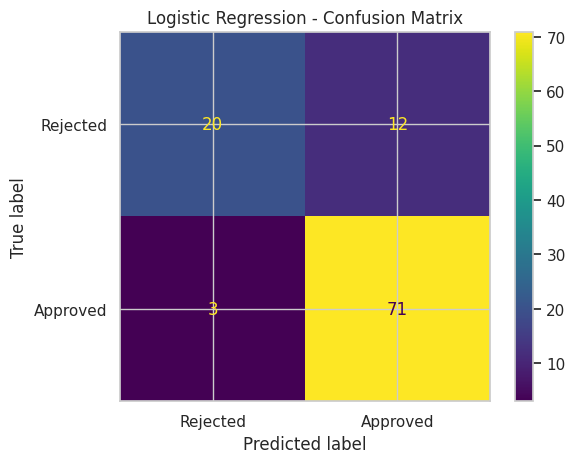

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
)

disp.plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(20)

,Actual,Predicted
0,1,1
1,1,1
2,1,1
3,0,0
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


In [ ]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient,Absolute_Coefficient
9,Credit_History,3.350129,3.350129
13,Log_LoanAmount,0.853042,0.853042
16,LoanToIncome,-0.755429,0.755429
19,Property_Area_Semiurban,0.476296,0.476296
3,Education,-0.420069,0.420069
7,LoanAmount,-0.367760,0.367760
12,Log_CoapplicantIncome,0.349120,0.349120
1,Married,0.338833,0.338833
4,Self_Employed,-0.313283,0.313283
6,CoapplicantIncome,-0.311745,0.311745


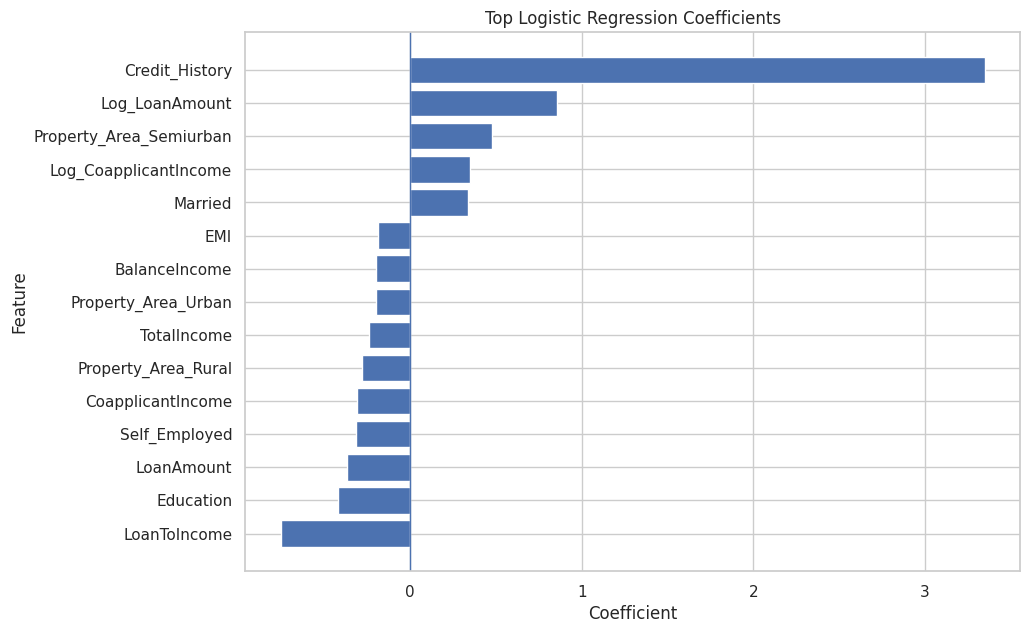

In [ ]:
top_features = coefficients.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linewidth=1)

plt.title("Top Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()

In [ ]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "SVM": SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    )
}

print("Number of models:", len(models))

Number of models: 8


In [ ]:
results = []

for name, model in models.items():

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.858491,0.855422,0.959459,0.904459
1,Extra Trees,0.858491,0.847059,0.972973,0.905660
2,Random Forest,0.830189,0.850000,0.918919,0.883117
3,SVM,0.830189,0.825581,0.959459,0.887500
4,Hist Gradient Boosting,0.820755,0.857143,0.891892,0.874172
5,Decision Tree,0.801887,0.827160,0.905405,0.864516
6,Gradient Boosting,0.801887,0.835443,0.891892,0.862745
7,KNN,0.726415,0.747253,0.918919,0.824242


In [ ]:
results_display = results_df.copy()

for column in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]:
    results_display[column] = (
        results_display[column] * 100
    ).round(2)

results_display

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,85.85,85.54,95.95,90.45
1,Extra Trees,85.85,84.71,97.30,90.57
2,Random Forest,83.02,85.00,91.89,88.31
3,SVM,83.02,82.56,95.95,88.75
4,Hist Gradient Boosting,82.08,85.71,89.19,87.42
5,Decision Tree,80.19,82.72,90.54,86.45
6,Gradient Boosting,80.19,83.54,89.19,86.27
7,KNN,72.64,74.73,91.89,82.42
